# 5. Dependencia temporal y estacionariedad

La dependencia se estudia en escala horaria; las pruebas de raíz unitaria y estacionariedad se aplican a la media diaria y a su diferencia.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/processed/panel_horario.parquet').exists())
plt.rcParams.update({'figure.figsize':(10,4),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})
panel = pq.read_table(ROOT/'data/processed/panel_horario.parquet', filters=[('inicio','<',pd.Timestamp('2022-01-01',tz='America/Bogota'))]).to_pandas()
assert panel.index.max() < pd.Timestamp('2022-01-01',tz='America/Bogota')
assert panel.index.is_monotonic_increasing and panel.index.is_unique
y = panel['y_demanda_real_kwh']
gwh = y / 1e6
registro = json.loads((ROOT/'data/processed/feature_registry.json').read_text(encoding='utf-8'))


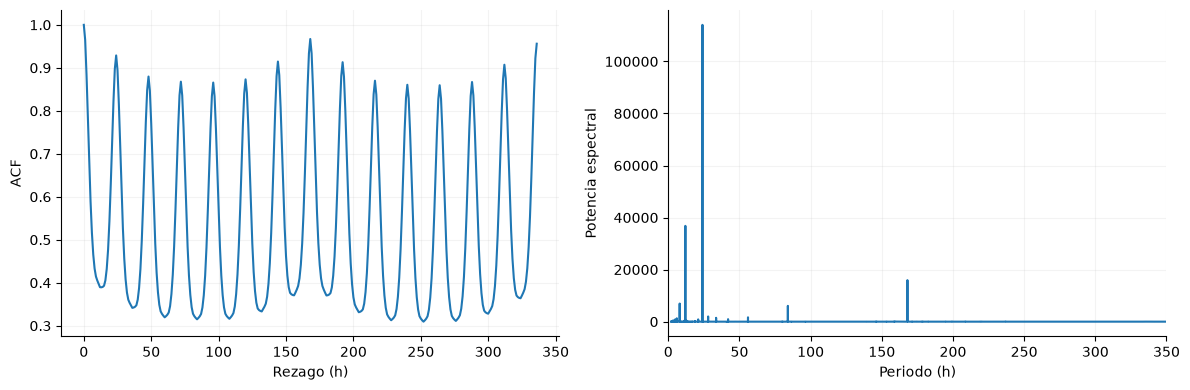

In [2]:
from statsmodels.tsa.stattools import acf,adfuller,kpss
from scipy.signal import periodogram
v=acf(gwh,nlags=336,fft=True); a24=float(v[24]); a168=float(v[168]); fig,axes=plt.subplots(1,2,figsize=(12,4)); axes[0].plot(range(337),v); axes[0].set(xlabel='Rezago (h)',ylabel='ACF'); f,p=periodogram(gwh.to_numpy(),detrend='linear'); sel=(f>0)&(1/np.maximum(f,1e-12)<1000); axes[1].plot(1/f[sel],p[sel]); axes[1].set(xlabel='Periodo (h)',ylabel='Potencia espectral',xlim=(0,350)); fig.tight_layout(); display(fig); plt.close(fig)

La autocorrelación a 24 y 168 horas es 0.929 y 0.967, respectivamente. El espectro complementa estos rezagos al localizar ciclos; la tendencia puede elevar la ACF global y no debe confundirse con capacidad predictiva fuera de muestra.

In [3]:
import warnings
registros=[]
for nombre,serie in [('Media diaria',gwh.resample('D').mean()),('Diferencia diaria',gwh.resample('D').mean().diff().dropna())]:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore'); a=adfuller(serie,maxlag=30,autolag='AIC'); k=kpss(serie,regression='c',nlags='auto')
    registros.append({'serie':nombre,'ADF_estadistico':a[0],'ADF_p':a[1],'KPSS_estadistico':k[0],'KPSS_p_tabulado':k[1]})
display(pd.DataFrame(registros))

,serie,ADF_estadistico,ADF_p,KPSS_estadistico,KPSS_p_tabulado
0,Media diaria,-1.970757,0.29954,14.164022,0.01
1,Diferencia diaria,-22.279932,0.00000,0.020103,0.10


ADF contrasta raíz unitaria y KPSS estacionariedad alrededor de una constante. Se interpretan conjuntamente a frecuencia diaria. Los p de KPSS pueden corresponder al límite de su tabla; una diferencia no garantiza estabilidad frente a rupturas.

## Memoria tras retirar el ciclo semanal

La diferencia semanal horaria elimina la comparación entre horas de distinto día de semana. Su ACF y PACF permiten examinar dependencia remanente; los picos negativos cercanos a 168 horas también pueden surgir por la propia diferenciación.

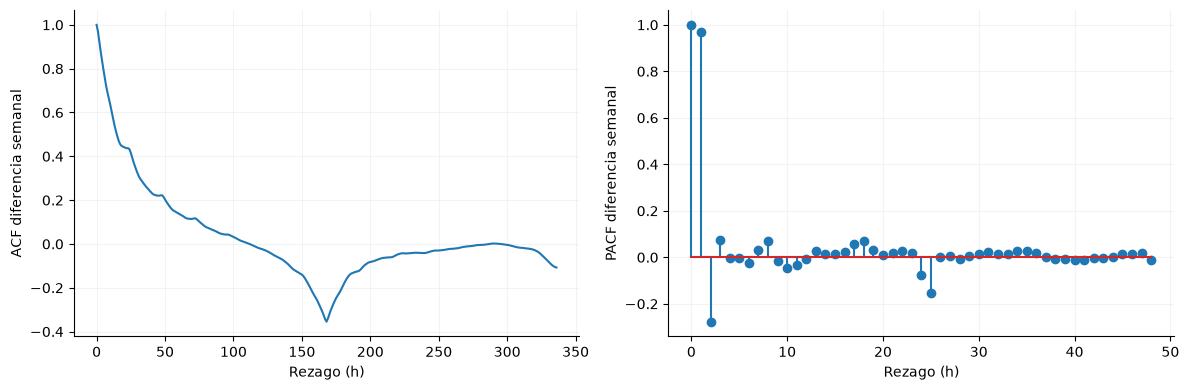

In [4]:
from statsmodels.tsa.stattools import pacf
dif_sem=gwh.diff(168).dropna()
acf_dif=acf(dif_sem,nlags=336,fft=True); pacf_dif=pacf(dif_sem,nlags=48,method='ywmle')
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(np.arange(337),acf_dif); axes[0].set(xlabel='Rezago (h)',ylabel='ACF diferencia semanal')
axes[1].stem(np.arange(49),pacf_dif); axes[1].set(xlabel='Rezago (h)',ylabel='PACF diferencia semanal')
fig.tight_layout(); display(fig); plt.close(fig)
acf_1=float(acf_dif[1]); pacf_24=float(pacf_dif[24])


La diferencia semanal conserva ACF de 0.97 a una hora y PACF de -0.07 a 24 horas. Restar la semana anterior no agota necesariamente la memoria reciente; estos diagnósticos respaldan estudiar conjuntamente historia corta y calendario, sin interpretar cada rezago como un contraste independiente.

## Variación de la dispersión y dependencia residual

La mediana y la desviación absoluta mediana móviles se calculan sobre diferencias semanales diarias con ventanas retrospectivas de 90 días. Ljung–Box y ARCH se aplican sólo a entrenamiento sobre esa diferencia centrada. Al no tratarse de innovaciones de un modelo ajustado, los resultados describen dependencia y agrupación de magnitudes; una señal ARCH también puede estar afectada por autocorrelación remanente.

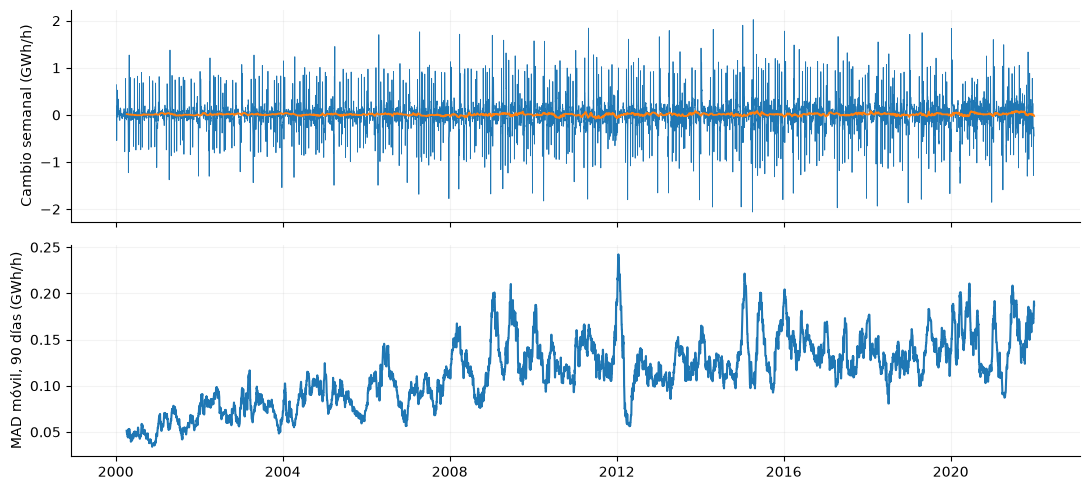

,contraste,estadistico,p_sin_ajustar
0,Ljung–Box 7 días,3305.246435,0.000000e+00
1,Ljung–Box 14 días,3641.656019,0.000000e+00
2,ARCH 7 días,1260.880336,4.814710e-268
3,"BDS dimensión 2, últimos 1000 días de train",6.271635,3.572758e-10


In [5]:
from statsmodels.stats.diagnostic import acorr_ljungbox,het_arch
from statsmodels.tsa.stattools import bds
d_sem=gwh.resample('D').mean().diff(7).dropna()
mediana_mov=d_sem.rolling(90,min_periods=90).median()
mad_mov=d_sem.rolling(90,min_periods=90).apply(lambda x:np.median(np.abs(x-np.median(x))),raw=True)
fig,axes=plt.subplots(2,1,figsize=(11,5),sharex=True)
axes[0].plot(d_sem.index,d_sem,lw=.6); axes[0].plot(mediana_mov.index,mediana_mov,lw=1.3); axes[0].set_ylabel('Cambio semanal (GWh/h)')
axes[1].plot(mad_mov.index,mad_mov); axes[1].set_ylabel('MAD móvil, 90 días (GWh/h)')
fig.tight_layout(); display(fig); plt.close(fig)
mad_min=float(mad_mov.dropna().min()); mad_max=float(mad_mov.max())
e=d_sem.loc[d_sem.index<'2018-01-01']; e=e-e.mean()
lb=acorr_ljungbox(e,lags=[7,14],return_df=True)
lm,p_arch,_,_=het_arch(e,nlags=7,result_object=False)
bds_stat,bds_p=bds(e.iloc[-1000:].to_numpy(),max_dim=2)
diagnosticos=pd.DataFrame([
    {'contraste':'Ljung–Box 7 días','estadistico':lb.loc[7,'lb_stat'],'p_sin_ajustar':lb.loc[7,'lb_pvalue']},
    {'contraste':'Ljung–Box 14 días','estadistico':lb.loc[14,'lb_stat'],'p_sin_ajustar':lb.loc[14,'lb_pvalue']},
    {'contraste':'ARCH 7 días','estadistico':lm,'p_sin_ajustar':p_arch},
    {'contraste':'BDS dimensión 2, últimos 1000 días de train','estadistico':float(bds_stat),'p_sin_ajustar':float(bds_p)}])
display(diagnosticos)
p_lb=float(lb.loc[14,'lb_pvalue'])


La MAD móvil varía entre 0.034 y 0.242 GWh/h, mostrando cuánto cambia la dispersión local de las diferencias semanales. Ljung–Box a 14 días obtiene p = 0; los contrastes son exploratorios y no comparan modelos. BDS contrasta independencia e idéntica distribución: su rechazo, en una serie con memoria, no aísla no linealidad. La heterocedasticidad se revisará después sobre errores predictivos genuinos.

**Decisión.** Conservar rezagos diarios y semanales como referencias temporales.

**Impacto.** Permite evaluar memoria y ciclos presentes en los datos.

**Riesgo.** La persistencia y la tendencia pueden generar correlaciones altas sin mejoras de pronóstico.